# Ship ADCP quick-look (VmDas)

Quick-look of VmDas ship ADCP data (`.LTA` / `.STA`) during a cruise.

Reads the RDI PD0 binary files written by VmDas, converts the ship-relative velocities to absolute (Earth-referenced) currents, applies basic QC and produces:

- time-depth sections of u, v and speed
- a map of the ship track with currents averaged over a depth layer
- a NetCDF file with the processed data

**Notes**

- Use only closed files: copy them from the acquisition PC instead of reading files VmDas is still writing. Incomplete ensembles at the end of a file are skipped anyway.
- Velocities in `.LTA` / `.STA` are **relative to the ship**. Absolute currents are obtained by adding the ship velocity from GPS (`REF = "nav"`) or from bottom track (`REF = "bt"`). Bottom track is lost off the shelf, so GPS is the default.
- VmDas does not flag bins below the bottom unless `PRMarkBadBelowBottom=TRUE` in the `.VMO`. Here they are masked using the bottom-track depth.
- This is a quick-look tool for use at sea. It does **not** replace proper post-processing (e.g. CODAS / pycurrents), which calibrates transducer misalignment and scale factor.

Requirements: `numpy`, `xarray`, `matplotlib`, `netCDF4`

In [13]:
import glob
import os
import re
import struct
from datetime import datetime, timedelta

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

%matplotlib inline

## Configuration

In [25]:
DATA_DIR = "ADCP_data"     # folder with the VmDas files (closed files only)
DEPLOYMENT = "SOCIB_CabreraSummer26004"  # name as in the file names (DeploymentName + 3-digit number);
                                         # output files are named after it
EXT = "STA"                # "LTA", "STA" or "ENX"
REF = "nav"                # reference for absolute velocities: "nav" (GPS) or "bt" (bottom track)

LAYER = (20, 60)           # depth layer (m) for the map vectors
VMAX = 0.5                 # colour limit for the sections (m/s)
MAX_DEPTH = None           # max depth in the sections (m); None = automatic
TRANSDUCER_DEPTH = None    # transducer depth (m); None = read from the .VMO

# QC
PG_MIN = 50                # minimum percent good (4-beam solutions)
ERR_MAX = 0.2              # maximum absolute error velocity (m/s)
SIDELOBE = 0.85            # mask bins deeper than SIDELOBE * bottom range (~cos 30 deg)
DV_MAX = 1.0               # mask ensembles where the ship velocity jumps more than this (m/s); None disables

# Output
OUTDIR = "quicklook"
SAVE_FIGS = True
SAVE_NC = False

## Constants and PD0 reader

Reads RDI PD0 ensembles by data type ID (fixed and variable leaders, velocity, echo, percent good, bottom track and the VmDas navigation block).

In [26]:
BAD_VEL = -32768
BAM32 = 180.0 / 2**31  # binary angle -> degrees (32 bit)
BAM16 = 180.0 / 2**15  # binary angle -> degrees (16 bit)

# PD0 data type IDs used by VmDas
ID_FIXED = 0x0000
ID_VAR = 0x0080
ID_VEL = 0x0100
ID_CORR = 0x0200
ID_ECHO = 0x0300
ID_PG = 0x0400
ID_BT = 0x0600
ID_NAV = 0x2000


def _iter_ensembles(buf):
    """Yield (start, nbytes) of each complete ensemble with a valid checksum.

    Incomplete ensembles at the end of the file (file still being written)
    and corrupted ensembles are skipped.
    """
    i, n = 0, len(buf)
    while i < n - 4:
        if buf[i] == 0x7F and buf[i + 1] == 0x7F:
            nbytes = struct.unpack_from("<H", buf, i + 2)[0]
            end = i + nbytes + 2
            if nbytes > 6 and end <= n:
                checksum = struct.unpack_from("<H", buf, i + nbytes)[0]
                if sum(buf[i : i + nbytes]) & 0xFFFF == checksum:
                    yield i, nbytes
                    i = end
                    continue
        i += 1


def _decode_nav(buf, o):
    """Decode the VmDas navigation block (ID 0x2000) starting at offset o."""
    day, month = buf[o + 2], buf[o + 3]
    year = struct.unpack_from("<H", buf, o + 4)[0]
    t1, _, lat1, lon1, t2, lat2, lon2 = struct.unpack_from("<iiiiiii", buf, o + 6)
    spd, trk = struct.unpack_from("<hH", buf, o + 34)
    out = dict(lat1=np.nan, lon1=np.nan, lat2=np.nan, lon2=np.nan,
               t1=None, t2=None, nav_speed=spd / 1000.0, nav_track=trk * BAM16)
    try:
        d0 = datetime(year, month, day)
    except ValueError:
        return out
    out["t1"] = d0 + timedelta(seconds=t1 / 1e4)
    out["t2"] = d0 + timedelta(seconds=t2 / 1e4)
    if out["t2"] < out["t1"]:  # crossed midnight
        out["t2"] += timedelta(days=1)
    if lat1 != 0 or lon1 != 0:
        out["lat1"], out["lon1"] = lat1 * BAM32, lon1 * BAM32
    if lat2 != 0 or lon2 != 0:
        out["lat2"], out["lon2"] = lat2 * BAM32, lon2 * BAM32
    return out


def read_pd0(path):
    """Read one VmDas PD0 file (.LTA, .STA, .ENX) into a list of dicts."""
    with open(path, "rb") as f:
        buf = f.read()

    records = []
    for start, _ in _iter_ensembles(buf):
        ndt = buf[start + 5]
        offsets = struct.unpack_from("<%dH" % ndt, buf, start + 6)
        blocks = {struct.unpack_from("<H", buf, start + o)[0]: start + o for o in offsets}
        if ID_FIXED not in blocks or ID_VAR not in blocks or ID_VEL not in blocks:
            continue

        o = blocks[ID_FIXED]
        ncells = buf[o + 9]
        cell = struct.unpack_from("<H", buf, o + 12)[0] / 100.0
        bin1 = struct.unpack_from("<H", buf, o + 32)[0] / 100.0
        coord = (buf[o + 25] >> 3) & 0b11  # 3 = Earth

        o = blocks[ID_VAR]
        yy, mo, dd, hh, mi, ss, hs = buf[o + 4 : o + 11]
        try:
            adcp_time = datetime(2000 + yy, mo, dd, hh, mi, ss) + timedelta(seconds=hs / 100)
        except ValueError:
            adcp_time = None
        r = dict(
            ens=struct.unpack_from("<H", buf, o + 2)[0] + 65536 * buf[o + 11],
            adcp_time=adcp_time,
            heading=struct.unpack_from("<H", buf, o + 18)[0] / 100.0,
            pitch=struct.unpack_from("<h", buf, o + 20)[0] / 100.0,
            roll=struct.unpack_from("<h", buf, o + 22)[0] / 100.0,
            temperature=struct.unpack_from("<h", buf, o + 26)[0] / 100.0,
            ncells=ncells, cell=cell, bin1=bin1, coord=coord,
        )

        def _profile(bid, dtype):
            if bid not in blocks:
                return np.full((ncells, 4), np.nan)
            a = np.frombuffer(buf, dtype=dtype, count=ncells * 4,
                              offset=blocks[bid] + 2).reshape(ncells, 4)
            return a.astype(float)

        vel = _profile(ID_VEL, "<i2")
        vel[vel == BAD_VEL] = np.nan
        r["vel"] = vel / 1000.0  # m/s
        r["echo"] = _profile(ID_ECHO, "u1").mean(axis=1)
        r["pg"] = _profile(ID_PG, "u1")[:, 3]  # beam 4 = % good 4-beam solutions in Earth coords

        if ID_BT in blocks:
            o = blocks[ID_BT]
            rng = np.array(struct.unpack_from("<4H", buf, o + 16), float) / 100.0
            rng[rng == 0] = np.nan
            btv = np.array(struct.unpack_from("<4h", buf, o + 24), float)
            btv[btv == BAD_VEL] = np.nan
            r["bt_range"] = np.nanmean(rng) if np.isfinite(rng).any() else np.nan
            r["bt_u"], r["bt_v"] = btv[0] / 1000.0, btv[1] / 1000.0
        else:
            r["bt_range"] = r["bt_u"] = r["bt_v"] = np.nan

        if ID_NAV in blocks:
            r.update(_decode_nav(buf, blocks[ID_NAV]))
        else:
            r.update(lat1=np.nan, lon1=np.nan, lat2=np.nan, lon2=np.nan,
                     t1=None, t2=None, nav_speed=np.nan, nav_track=np.nan)
        records.append(r)
    return records


def read_vmo(path):
    """Return a dict with a few useful settings from a VmDas .VMO file."""
    keys = {
        "TransducerDepth(meters)": "transducer_depth",
        "FirstAvgTime": "sta_seconds",
        "SecondAvgTime": "lta_seconds",
        "AlignmentOffsetEA": "alignment_EA",
        "VelocityScaleFactorForProfileAndWTVelocities(unitless)": "scale_factor",
        "PRMarkBadBelowBottom": "mark_bad_below_bottom",
    }
    out = {}
    with open(path, errors="ignore") as f:
        for line in f:
            if "=" in line:
                k, v = line.strip().split("=", 1)
                if k in keys and keys[k] not in out:
                    out[keys[k]] = v
    return out


# VmDas file names: <DeploymentName><NNN>_<SSSSSS>.<EXT>
# NNN = deployment number, SSSSSS = file sequence number
VMDAS_NAME = re.compile(r"^(?P<name>.*?)(?P<num>\d{3})_(?P<seq>\d{6})\.(?P<ext>\w+)$")


def list_deployments(data_dir, ext="LTA"):
    """Return {deployment: [files sorted by sequence number]} for one file type.

    deployment is the file name prefix, e.g. 'SOCIB_CabreraSummer26004'.
    """
    out = {}
    for f in os.listdir(data_dir):
        m = VMDAS_NAME.match(f)
        if m and m.group("ext").upper() == ext.upper():
            dep = m.group("name") + m.group("num")
            out.setdefault(dep, []).append((int(m.group("seq")), os.path.join(data_dir, f)))
    return {d: [f for _, f in sorted(v)] for d, v in sorted(out.items())}


def select_deployment(data_dir, deployment, ext="LTA"):
    """Return the files of one deployment, sorted by sequence number.

    deployment : full name as in the file names, e.g. 'SOCIB_CabreraSummer26004'
                 (VmDas DeploymentName + 3-digit DeploymentNumber)
    """
    deps = list_deployments(data_dir, ext)
    if not deps:
        raise FileNotFoundError("No VmDas *.%s files in %s" % (ext, data_dir))
    if deployment not in deps:
        available = "\n  ".join("%s (%d files)" % (d, len(f)) for d, f in deps.items())
        raise ValueError("Deployment %r not found in %s. Available:\n  %s"
                         % (deployment, data_dir, available))
    return deps[deployment]


def load(data_dir, deployment, ext="LTA", transducer_depth=None):
    """Read all files of one deployment and file type into an xarray Dataset."""
    dep = deployment
    files = select_deployment(data_dir, deployment, ext)

    vmo = {}
    vmo_files = list_deployments(data_dir, "VMO").get(dep, [])
    if vmo_files:
        vmo = read_vmo(vmo_files[0])
    else:
        print("WARNING: no .VMO file found for %s" % dep)
    if transducer_depth is None:
        transducer_depth = float(vmo.get("transducer_depth", 0.0))

    recs = []
    for f in files:
        recs.extend(read_pd0(f))
    if not recs:
        raise RuntimeError("No complete ensembles found")

    r0 = recs[0]
    if r0["coord"] != 3:
        print("WARNING: data are not in Earth coordinates (EX bits = %d)" % r0["coord"])

    # The bin setup should not change within a deployment; if it does, keep the
    # first configuration and report what is dropped
    # (bin 1 distance jitters by ~1 cm between ensembles, so compare with a tolerance)
    cfg0 = (r0["ncells"], r0["cell"], r0["bin1"])

    def same_cfg(r):
        return (r["ncells"] == cfg0[0] and abs(r["cell"] - cfg0[1]) < 0.01
                and abs(r["bin1"] - cfg0[2]) < 0.1 * cfg0[1])

    n_all = len(recs)
    recs = [r for r in recs if same_cfg(r)]
    if len(recs) < n_all:
        print("WARNING: bin configuration changes within %s. Kept %d of %d ensembles "
              "(%d bins of %.1f m); the rest were dropped." % (dep, len(recs), n_all,
                                                              cfg0[0], cfg0[1]))
    ncells = r0["ncells"]
    depth = transducer_depth + r0["bin1"] + r0["cell"] * np.arange(ncells)

    def col(k):
        return np.array([r[k] for r in recs], dtype=float)

    # Time: midpoint between first and last GPS fix (UTC); fall back to ADCP clock
    time = []
    for r in recs:
        if r["t1"] is not None and r["t2"] is not None:
            time.append(r["t1"] + (r["t2"] - r["t1"]) / 2)
        else:
            time.append(r["adcp_time"])
    time = np.array(time, dtype="datetime64[ns]")

    # Ship velocity over ground from the first/last GPS fixes of each average
    lat1, lon1, lat2, lon2 = col("lat1"), col("lon1"), col("lat2"), col("lon2")
    dt = np.array([(r["t2"] - r["t1"]).total_seconds() if r["t1"] else np.nan
                   for r in recs])
    dt[dt <= 0] = np.nan
    R = 6371000.0
    latm = np.deg2rad((lat1 + lat2) / 2)
    ship_u = np.deg2rad(lon2 - lon1) * R * np.cos(latm) / dt
    ship_v = np.deg2rad(lat2 - lat1) * R / dt

    vel = np.stack([r["vel"] for r in recs])  # (time, depth, 4)

    ds = xr.Dataset(
        data_vars=dict(
            u_rel=(("time", "depth"), vel[:, :, 0]),
            v_rel=(("time", "depth"), vel[:, :, 1]),
            w=(("time", "depth"), vel[:, :, 2]),
            err_vel=(("time", "depth"), vel[:, :, 3]),
            echo=(("time", "depth"), np.stack([r["echo"] for r in recs])),
            pg=(("time", "depth"), np.stack([r["pg"] for r in recs])),
            lat=("time", np.where(np.isfinite(lat2), (lat1 + lat2) / 2, lat1)),
            lon=("time", np.where(np.isfinite(lon2), (lon1 + lon2) / 2, lon1)),
            ship_u=("time", ship_u),
            ship_v=("time", ship_v),
            bt_u=("time", col("bt_u")),
            bt_v=("time", col("bt_v")),
            bt_depth=("time", col("bt_range") + transducer_depth),
            heading=("time", col("heading")),
            pitch=("time", col("pitch")),
            roll=("time", col("roll")),
            temperature=("time", col("temperature")),
            ens=("time", col("ens")),
        ),
        coords=dict(time=time, depth=depth),
        attrs=dict(
            deployment=dep,
            source_files=", ".join(os.path.basename(f) for f in files),
            file_type=ext,
            transducer_depth_m=transducer_depth,
            **{"vmdas_" + k: str(v) for k, v in vmo.items()},
        ),
    )
    ds = ds.sortby("time")
    _, keep = np.unique(ds.time.values, return_index=True)
    ds = ds.isel(time=np.sort(keep))

    units = dict(u_rel="m/s", v_rel="m/s", w="m/s", err_vel="m/s", echo="counts",
                 pg="%", lat="degrees_north", lon="degrees_east", ship_u="m/s",
                 ship_v="m/s", bt_u="m/s", bt_v="m/s", bt_depth="m", heading="degrees",
                 pitch="degrees", roll="degrees", temperature="degC")
    for k, u in units.items():
        ds[k].attrs["units"] = u
    ds["depth"].attrs.update(units="m", positive="down")
    ds["u_rel"].attrs["long_name"] = "Eastward water velocity relative to the ship"
    ds["v_rel"].attrs["long_name"] = "Northward water velocity relative to the ship"
    ds["ship_u"].attrs["long_name"] = "Eastward ship velocity from GPS fixes"
    ds["ship_v"].attrs["long_name"] = "Northward ship velocity from GPS fixes"
    ds["bt_u"].attrs["long_name"] = "Eastward bottom velocity relative to the ship (bottom track)"
    ds["bt_v"].attrs["long_name"] = "Northward bottom velocity relative to the ship (bottom track)"
    return ds


## Processing and QC

In [27]:
def process(ds, ref="nav", pg_min=50, err_max=0.2, sidelobe=0.85, dv_max=1.0):
    """Compute absolute velocities and apply basic QC.

    ref      : 'nav' (GPS ship velocity) or 'bt' (bottom track)
    pg_min   : minimum percent good (4-beam solutions)
    err_max  : maximum absolute error velocity (m/s)
    sidelobe : bins deeper than sidelobe * bottom range (from the
               transducer) are masked. 0.85 ~ cos(30 deg) for a 30 deg beam.
    dv_max   : ensembles where the ship velocity differs from a neighbouring
               ensemble by more than dv_max (m/s) are masked. These are
               averages that include a start/stop or a sharp turn, where the
               ship velocity is poorly removed. None disables the test.
    """
    if ref == "nav":
        su, sv = ds.ship_u, ds.ship_v
    elif ref == "bt":
        su, sv = -ds.bt_u, -ds.bt_v  # BT measures the bottom moving relative to the ship
    else:
        raise ValueError("ref must be 'nav' or 'bt'")

    u = ds.u_rel + su
    v = ds.v_rel + sv

    good = ds.pg >= pg_min
    good &= np.abs(ds.err_vel) <= err_max
    tdepth = ds.attrs["transducer_depth_m"]
    bottom_cut = tdepth + sidelobe * (ds.bt_depth - tdepth)
    good &= ~(ds.depth > bottom_cut)  # NaN bottom (no BT) -> no masking

    ship_changing = np.zeros(ds.sizes["time"], bool)
    if dv_max is not None and ds.sizes["time"] > 1:
        su_, sv_ = su.values, sv.values
        spd = np.hypot(su_, sv_)
        dv = np.nan_to_num(np.hypot(np.diff(su_), np.diff(sv_)))
        prev_d = np.r_[np.inf, dv]   # difference with previous ensemble
        next_d = np.r_[dv, np.inf]   # difference with next ensemble
        prev_s = np.r_[np.inf, spd[:-1]]
        next_s = np.r_[spd[1:], np.inf]
        # Changing: differs from both neighbours (start/stop in progress or turn)...
        ship_changing = (prev_d > dv_max) & (next_d > dv_max)
        # ...but not a short station between two transits (slower than both neighbours)
        station = spd < np.fmin(prev_s, next_s) - dv_max
        ship_changing &= ~station
        ship_changing[np.isinf(prev_d) & np.isinf(next_d)] = False
        good &= xr.DataArray(~ship_changing, dims="time")
    ds["ship_changing"] = ("time", ship_changing.astype("int8"))
    ds["ship_changing"].attrs["long_name"] = "1 = masked: ship speed/course changing (start, stop or turn)"

    ds["u"] = u.where(good)
    ds["v"] = v.where(good)
    ds["speed"] = np.hypot(ds.u, ds.v)
    ds["u"].attrs = dict(units="m/s", long_name="Eastward absolute current (ref=%s)" % ref)
    ds["v"].attrs = dict(units="m/s", long_name="Northward absolute current (ref=%s)" % ref)
    ds["speed"].attrs = dict(units="m/s", long_name="Current speed")
    ds.attrs.update(reference=ref, qc_pg_min=pg_min, qc_err_max=err_max,
                    qc_sidelobe=sidelobe, qc_dv_max=str(dv_max))
    return ds


def output_stem(ds):
    """Output file name: deployment name + file sequence range + file type.

    One file : SOCIB_CabreraSummer26004_000000_STA
    Several  : SOCIB_CabreraSummer26004_000000-000003_STA
    '_bt' is appended when bottom track is used as reference.
    """
    seqs = [VMDAS_NAME.match(f.strip()).group("seq") for f in ds.attrs["source_files"].split(",")]
    name = "%s_%s" % (ds.attrs["deployment"], seqs[0])
    if len(seqs) > 1:
        name += "-" + seqs[-1]
    name += "_" + ds.attrs["file_type"]
    if ds.attrs.get("reference") == "bt":
        name += "_bt"
    return name


## Plot functions

In [28]:
def _with_gaps(ds, factor=3):
    """Insert empty profiles in time gaps so sections show them blank.

    A gap is any interval longer than factor x the typical ensemble interval.
    Two NaN profiles are added inside each gap, one interval after the last
    profile and one before the next, so pcolormesh does not stretch the data
    across the gap.
    """
    if ds.sizes["time"] < 3:
        return ds
    t = ds.time.values
    dt = np.diff(t)
    step = np.median(dt)
    gaps = np.where(dt > factor * step)[0]
    if gaps.size == 0:
        return ds
    new_t = np.concatenate([np.r_[t[i] + step, t[i + 1] - step] for i in gaps])
    empty = ds.isel(time=slice(0, 1)).squeeze("time", drop=True)
    empty = xr.full_like(empty, np.nan).expand_dims(time=new_t)
    return xr.concat([ds, empty], dim="time", data_vars="all").sortby("time")


def plot_sections(ds, outfile=None, vmax=0.5, max_depth=None):
    ymax = max_depth or float(ds.depth.where(ds.u.notnull().any("time")).max()) + 10
    dsp = _with_gaps(ds[["u", "v", "speed", "bt_depth"]])
    fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True, constrained_layout=True)
    panels = [("u", "u (east) [m/s]", "RdBu_r", -vmax, vmax),
              ("v", "v (north) [m/s]", "RdBu_r", -vmax, vmax),
              ("speed", "speed [m/s]", "viridis", 0, vmax)]
    for ax, (var, label, cmap, lo, hi) in zip(axes, panels):
        pc = ax.pcolormesh(dsp.time, dsp.depth, dsp[var].T, cmap=cmap, vmin=lo, vmax=hi,
                           shading="nearest")
        ax.plot(dsp.time, dsp.bt_depth, "k-", lw=1.2, label="bottom (BT)")
        fig.colorbar(pc, ax=ax, label=label, pad=0.01)
        ax.set_ylabel("depth [m]")
        ax.set_ylim(ymax, 0)
    axes[0].legend(loc="lower right", fontsize=8)
    axes[0].set_title("%s  |  ref = %s" % (output_stem(ds), ds.attrs["reference"]), fontsize=10)
    axes[-1].set_xlabel("time (UTC)")
    fig.autofmt_xdate()
    if outfile:
        fig.savefig(outfile, dpi=150)
    return fig


def plot_map(ds, outfile=None, layer=(20, 60), arrow_scale=None):
    lay = ds.sel(depth=slice(*layer))
    um, vm = lay.u.mean("depth"), lay.v.mean("depth")

    fig, ax = plt.subplots(figsize=(8, 8), constrained_layout=True)
    ax.plot(ds.lon, ds.lat, ".-", color="0.6", lw=1, ms=3, zorder=1)
    ok = np.isfinite(um) & np.isfinite(vm)
    if arrow_scale is None:
        span = max(float(ds.lon.max() - ds.lon.min()), float(ds.lat.max() - ds.lat.min()), 0.05)
        arrow_scale = 0.5 / (0.08 * span)  # 0.5 m/s ~ 8 % of the plot width
    q = ax.quiver(ds.lon[ok], ds.lat[ok], um[ok], vm[ok], np.hypot(um[ok], vm[ok]),
                  cmap="plasma", scale=arrow_scale, scale_units="xy", angles="uv",
                  width=0.004, zorder=3)
    ax.quiverkey(q, 0.85, 0.05, 0.5, "0.5 m/s", coordinates="axes")
    fig.colorbar(q, ax=ax, label="speed [m/s]", shrink=0.7)
    ax.plot(ds.lon[0], ds.lat[0], "g^", ms=9, label="start", zorder=4)
    ax.plot(ds.lon[-1], ds.lat[-1], "rs", ms=8, label="end", zorder=4)
    ax.set_aspect(1 / np.cos(np.deg2rad(float(ds.lat.mean()))))
    ax.set_xlabel("longitude")
    ax.set_ylabel("latitude")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", fontsize=8)
    t0 = str(ds.time.values[0])[:16].replace("T", " ")
    t1 = str(ds.time.values[-1])[:16].replace("T", " ")
    ax.set_title("Currents %d-%d m  |  %s - %s UTC" % (layer[0], layer[1], t0, t1), fontsize=10)
    if outfile:
        fig.savefig(outfile, dpi=150)
    return fig


## Load data

Deployments available in `DATA_DIR`:

In [29]:
for dep, files in list_deployments(DATA_DIR, EXT).items():
    print("%-35s %d %s files" % (dep, len(files), EXT))

SOCIB_CabreraSummer26004            1 STA files
SOCIB_CabreraSummer26005            1 STA files


In [30]:
ds = load(DATA_DIR, DEPLOYMENT, EXT, TRANSDUCER_DEPTH)
print("Deployment:", ds.attrs["deployment"])
print("%d ensembles, %s -> %s" % (ds.sizes["time"], str(ds.time.values[0])[:19],
                                 str(ds.time.values[-1])[:19]))
print("Files:", ds.attrs["source_files"])
print()
print("VmDas settings (.VMO):")
for k, v in ds.attrs.items():
    if k.startswith("vmdas_"):
        print("  %-24s %s" % (k[6:], v))

Deployment: SOCIB_CabreraSummer26004
89 ensembles, 2026-07-13T07:29:10 -> 2026-07-13T10:25:09
Files: SOCIB_CabreraSummer26004_000000.STA

VmDas settings (.VMO):
  mark_bad_below_bottom    FALSE
  alignment_EA             44.1
  scale_factor             1.0065
  sta_seconds              120
  lta_seconds              600
  transducer_depth         2


### Check: ship velocity from GPS vs bottom track

Where bottom track is available, the ship velocity from GPS should match minus the bottom-track velocity. A large mean difference points to a navigation, heading or calibration problem.

Ensembles with BT: 72 / 89
GPS - BT  u: mean -0.016, std 0.069 m/s
GPS - BT  v: mean 0.012, std 0.076 m/s


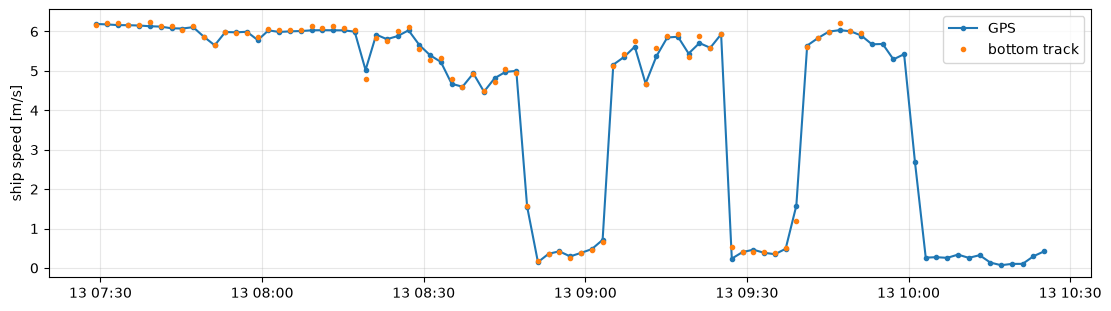

In [31]:
du = ds.ship_u + ds.bt_u
dv = ds.ship_v + ds.bt_v
n = int(np.isfinite(du).sum())
print("Ensembles with BT: %d / %d" % (n, ds.sizes["time"]))
if n:
    print("GPS - BT  u: mean %.3f, std %.3f m/s" % (float(du.mean()), float(du.std())))
    print("GPS - BT  v: mean %.3f, std %.3f m/s" % (float(dv.mean()), float(dv.std())))

fig, ax = plt.subplots(figsize=(11, 3), constrained_layout=True)
ax.plot(ds.time, np.hypot(ds.ship_u, ds.ship_v), ".-", label="GPS")
ax.plot(ds.time, np.hypot(ds.bt_u, ds.bt_v), ".", label="bottom track")
ax.set_ylabel("ship speed [m/s]")
ax.legend()
ax.grid(alpha=0.3)

## Absolute velocities and QC

In [32]:
ds = process(ds, ref=REF, pg_min=PG_MIN, err_max=ERR_MAX, sidelobe=SIDELOBE, dv_max=DV_MAX)

masked = ds.time.values[ds.ship_changing.values == 1]
print("Ensembles masked (ship starting/stopping/turning):",
      [str(t)[:16].replace("T", " ") for t in masked])
print("Valid data: %.0f %% of bins" % (100 * float(ds.u.notnull().mean())))

Ensembles masked (ship starting/stopping/turning): ['2026-07-13 08:49', '2026-07-13 09:03', '2026-07-13 09:39', '2026-07-13 10:01']
Valid data: 22 % of bins


## Sections

Output name: SOCIB_CabreraSummer26004_000000_STA


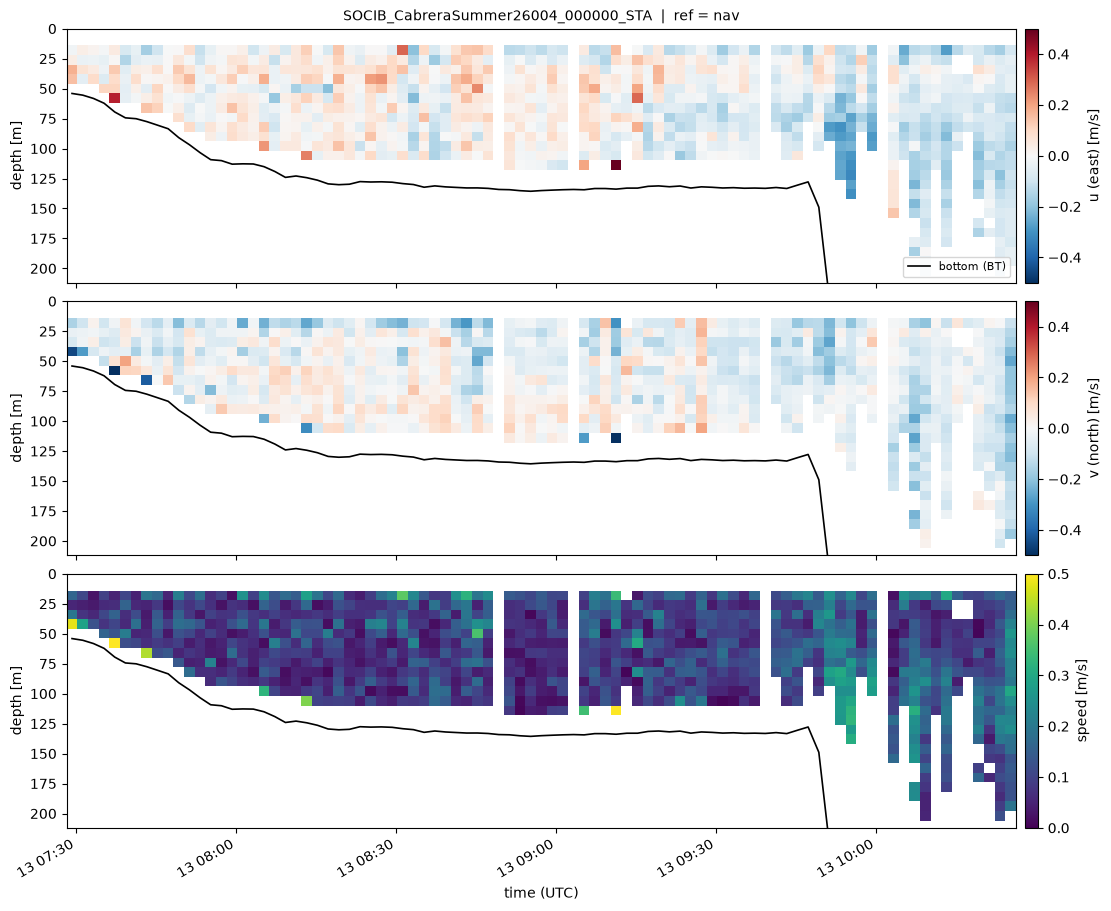

In [33]:
os.makedirs(OUTDIR, exist_ok=True)
stem = os.path.join(OUTDIR, output_stem(ds))
print("Output name:", output_stem(ds))

fig = plot_sections(ds, stem + "_sections.png" if SAVE_FIGS else None,
                    vmax=VMAX, max_depth=MAX_DEPTH)

## Map

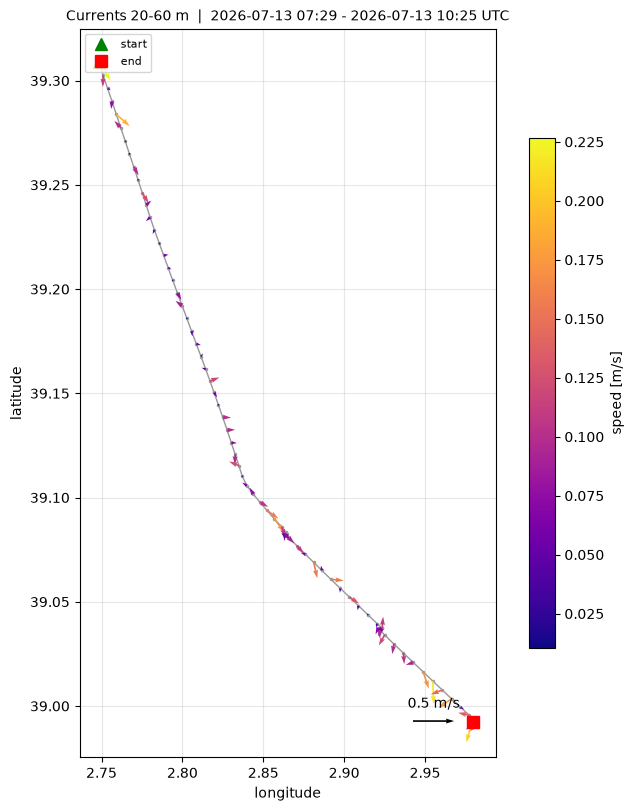

In [34]:
fig = plot_map(ds, stem + "_map.png" if SAVE_FIGS else None, layer=LAYER)

## Save NetCDF

In [35]:
if SAVE_NC:
    ds.to_netcdf(stem + ".nc")
    print("Saved", os.path.abspath(stem + ".nc"))